# Single-molecule escape assay geometry inspection

This notebook compares a spherical bowl, a continuously cylindrically curved sheet, and a sinusoidal height field on the same voxel lattice. It first provides cross-sectional, overhead, and 3D geometry inspection, then uses `SELECTED_GEOMETRY` to run the receptor-resolved escape assay on any one of them.

In [141]:
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from utils.biosensor_mc import Params, derive
import utils.escape_assay as escape_assay_module
import utils.escape_assay_viz as escape_assay_viz_module
import utils.generate_geometries as generate_geometries_module

# Reload local modules so this cell also works after their source files change
# during an existing Jupyter kernel session.
importlib.reload(escape_assay_module)
importlib.reload(escape_assay_viz_module)
importlib.reload(generate_geometries_module)
from utils.escape_assay import (
    run_escape_assay,
    sample_receptor_faces,
    surface_release_locations,
)
from utils.escape_assay_viz import (
    export_escape_assay_run,
    load_escape_assay_run,
    plot_kaplan_meier_from_folder,
    plot_kaplan_meier_curves,
    plot_surface_metric_from_folder,
    plot_surface_metric_3d,
    summarize_receptor_trajectories,
)
from utils.generate_geometries import (
    make_cylindrically_curved_sheet_geometry,
    make_sinusoidal_height_field_geometry,
    make_spherical_bowl_geometry,
    sinusoidal_surface_curvatures,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", None)

## 1. Model and candidate geometries

All candidates use the same domain and lattice resolution. The cylindrically curved sheet bends the entire plane like a piece of paper, with constant nonzero principal curvature `1 / sheet_radius_m` and no surrounding flat rim. The two-dimensional sinusoidal field contains concave valleys, convex peaks, and intermediate local curvatures within one continuous surface.

In [142]:
nm = 1e-9

P = Params(
    Lx_m=100 * nm,
    Ly_m=100 * nm,
    H_m=50 * nm,
    a_m=1 * nm,
    D_m2_s=1e-11,
    receptor_density_m2=5e16,
    ligand_conc_M=0.0,
    k_on_M_inv_s=1e7,
    k_off_s=1e-2,
    open_boundaries=("z_max",),
    periodic_axes=("x", "y"),
    seed=7,
)

center_xy_m = (50 * nm, 50 * nm)
rim_z_m = 25 * nm

bowl_geometry = make_spherical_bowl_geometry(
    P,
    radius_m=25 * nm,
    depth_m=25 * nm,
    center_xy_m=center_xy_m,
    rim_z_m=rim_z_m,
    name="single_spherical_bowl",
)
sheet_half_span_m = 0.5 * (round(P.Lx_m / P.a_m) - 1) * P.a_m
# Exact curvature limits for a sheet centered on the lattice span:
#   planar:      sheet_radius_m = np.inf
#   semicircle:  sheet_radius_m = sheet_half_span_m
sheet_radius_m = sheet_half_span_m
sheet_edge_z_m = sheet_half_span_m
if np.isinf(sheet_radius_m):
    sheet_sagitta_m = 0.0
else:
    sheet_sagitta_m = sheet_half_span_m**2 / (
        sheet_radius_m + np.sqrt(sheet_radius_m**2 - sheet_half_span_m**2)
    )
sheet_vertex_z_m = sheet_edge_z_m - sheet_sagitta_m
curved_sheet_geometry = make_cylindrically_curved_sheet_geometry(
    P,
    radius_m=50 * nm, #sheet_radius_m,
    axis="y",
    center_xy_m=None,  # Exact midpoint of the lattice coordinate span.
    vertex_z_m=sheet_vertex_z_m,  # Keeps edge height fixed across radii.
    name="cylindrically_curved_sheet",
)
sinusoidal_geometry = make_sinusoidal_height_field_geometry(
    P,
    amplitude_m=15 * nm,
    wavelength_x_m=50 * nm,
    wavelength_y_m=50 * nm,
    mean_z_m=25 * nm,
    name="sinusoidal_height_field",
)

geometries = {
    "spherical_bowl": bowl_geometry,
    "cylindrical_sheet": curved_sheet_geometry,
    "sinusoidal_field": sinusoidal_geometry,
}
SELECTED_GEOMETRY = "cylindrical_sheet"
geometry = geometries[SELECTED_GEOMETRY]
G = derive(P, geometry)
escape_z_m = P.H_m

print(f"Selected geometry: {SELECTED_GEOMETRY}")
print(f"Grid: {G.Nx} x {G.Ny} x {G.Nz + 1} voxels")
print(f"Time step: {G.dt_s:.3e} s")
print(f"Reactive faces: {G.reactive_face_ids.size:,}")
print(f"Sampled receptors (before forcing release faces): {G.NR:,}")

Selected geometry: cylindrical_sheet
Grid: 100 x 100 x 51 voxels
Time step: 1.583e-08 s
Reactive faces: 18,400
Sampled receptors (before forcing release faces): 920


### Bound-interval waiting-time diagnostic

The accelerated assay samples the same discrete waiting-time law as repeated timestep-level dissociation tests: $N\sim\mathrm{Geometric}(p_{off})$, $p_{off}=1-e^{-k_{off}\Delta t}$, and $T_B=N\Delta t$. This cell compares sampled intervals with the continuous exponential limit. A short interval is possible even when the mean $1/k_{off}$ is long; however, `total_bound_time_s = 0` usually means that a released ligand never rebound, not that it dissociated instantaneously.

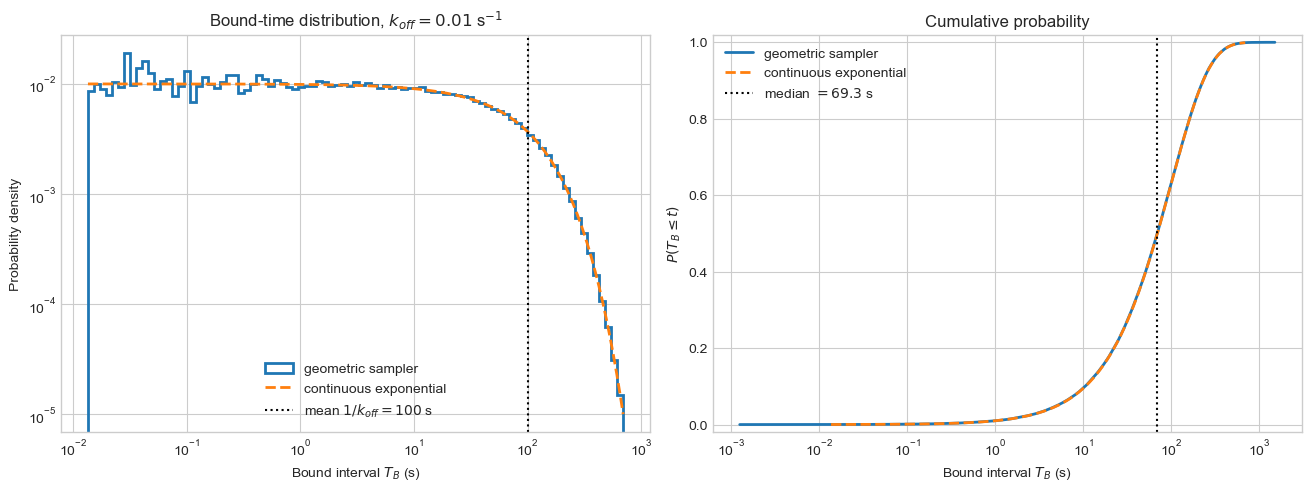

Lattice dt: 1.5833e-08 s
Per-step dissociation probability: 1.5833e-10
Continuous mean 1/k_off: 100 s
Exact discrete mean dt/p_off: 100 s
Sampled mean: 99.7056 s


,threshold_s,theoretical_P_T_less_than_threshold,sampled_P_T_less_than_threshold
0,0.001,0.000010,0.000000
1,0.010,0.000100,0.000085
2,0.100,0.001000,0.001040
3,1.000,0.009950,0.010030
4,10.000,0.095163,0.095880
5,100.000,0.632121,0.632735


In [143]:
DIAGNOSTIC_K_OFF_S = P.k_off_s
N_BOUND_WAIT_SAMPLES = 200_000
BOUND_WAIT_SEED = 9127

if DIAGNOSTIC_K_OFF_S <= 0:
    raise ValueError('DIAGNOSTIC_K_OFF_S must be positive.')
diagnostic_p_off = 1.0 - np.exp(-DIAGNOSTIC_K_OFF_S * G.dt_s)
diagnostic_rng = np.random.default_rng(BOUND_WAIT_SEED)
diagnostic_dwell_steps = diagnostic_rng.geometric(
    diagnostic_p_off, size=N_BOUND_WAIT_SAMPLES
)
diagnostic_bound_times_s = diagnostic_dwell_steps * G.dt_s

theoretical_mean_s = 1.0 / DIAGNOSTIC_K_OFF_S
discrete_mean_s = G.dt_s / diagnostic_p_off
theoretical_median_s = np.log(2.0) / DIAGNOSTIC_K_OFF_S
plot_upper_s = -np.log(1.0 - 0.999) / DIAGNOSTIC_K_OFF_S
positive_min_s = max(G.dt_s, np.quantile(diagnostic_bound_times_s, 1e-4))
histogram_edges_s = np.geomspace(positive_min_s, plot_upper_s, 90)
theory_x_s = np.geomspace(positive_min_s, plot_upper_s, 600)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].hist(
    diagnostic_bound_times_s, bins=histogram_edges_s, density=True,
    histtype='step', linewidth=2, label='geometric sampler',
)
axes[0].plot(
    theory_x_s, DIAGNOSTIC_K_OFF_S * np.exp(-DIAGNOSTIC_K_OFF_S * theory_x_s),
    linestyle='--', linewidth=2, label='continuous exponential',
)
axes[0].axvline(theoretical_mean_s, color='black', linestyle=':', label=rf'mean $1/k_{{off}}={theoretical_mean_s:.3g}$ s')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set(
    xlabel=r'Bound interval $T_B$ (s)', ylabel='Probability density',
    title=rf'Bound-time distribution, $k_{{off}}={DIAGNOSTIC_K_OFF_S:.2g}$ s$^{{-1}}$',
)
axes[0].legend()

sorted_bound_times_s = np.sort(diagnostic_bound_times_s)
empirical_cdf = np.arange(1, N_BOUND_WAIT_SAMPLES + 1) / N_BOUND_WAIT_SAMPLES
axes[1].plot(sorted_bound_times_s, empirical_cdf, linewidth=2, label='geometric sampler')
axes[1].plot(
    theory_x_s, 1.0 - np.exp(-DIAGNOSTIC_K_OFF_S * theory_x_s),
    linestyle='--', linewidth=2, label='continuous exponential',
)
axes[1].axvline(theoretical_median_s, color='black', linestyle=':', label=rf'median $={theoretical_median_s:.3g}$ s')
axes[1].set_xscale('log')
axes[1].set(
    xlabel=r'Bound interval $T_B$ (s)', ylabel=r'$P(T_B\leq t)$',
    ylim=(-0.02, 1.02), title='Cumulative probability',
)
axes[1].legend()
plt.show()

probability_thresholds_s = np.array([1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0])
bound_wait_summary = pd.DataFrame({
    'threshold_s': probability_thresholds_s,
    'theoretical_P_T_less_than_threshold': 1.0 - np.exp(-DIAGNOSTIC_K_OFF_S * probability_thresholds_s),
    'sampled_P_T_less_than_threshold': [
        np.mean(diagnostic_bound_times_s < threshold)
        for threshold in probability_thresholds_s
    ],
})
print(f'Lattice dt: {G.dt_s:.4e} s')
print(f'Per-step dissociation probability: {diagnostic_p_off:.4e}')
print(f'Continuous mean 1/k_off: {theoretical_mean_s:.6g} s')
print(f'Exact discrete mean dt/p_off: {discrete_mean_s:.6g} s')
print(f'Sampled mean: {diagnostic_bound_times_s.mean():.6g} s')
display(bound_wait_summary)


## 2. Sample receptors on the selected geometry

Set `SELECTED_GEOMETRY` above to `spherical_bowl`, `cylindrical_sheet`, or `sinusoidal_field`. One receptor layout is sampled from `P.receptor_density_m2` and reused unchanged throughout the assay. Every sampled receptor becomes a release location.

In [144]:
receptor_face_ids = sample_receptor_faces(P, geometry, seed=P.seed)
release_locations = surface_release_locations(
    geometry,
    face_ids=receptor_face_ids,
    prefix="receptor",
)
receptor_centers_nm = geometry.surface_centers_m[receptor_face_ids] / nm

print(f"Sampled {len(receptor_face_ids):,} receptors from the requested density.")
pd.DataFrame(
    receptor_centers_nm,
    columns=["surface_x_nm", "surface_y_nm", "surface_z_nm"],
).describe()

Sampled 920 receptors from the requested density.


,surface_x_nm,surface_y_nm,surface_z_nm
count,920.000000,920.000000,920.000000
mean,50.023913,48.761957,15.102174
std,33.495894,28.339210,12.661316
min,0.000000,0.000000,0.500000
25%,17.375000,24.750000,3.500000
50%,50.000000,48.000000,12.500000
75%,83.000000,72.000000,25.000000
max,99.000000,99.000000,42.500000


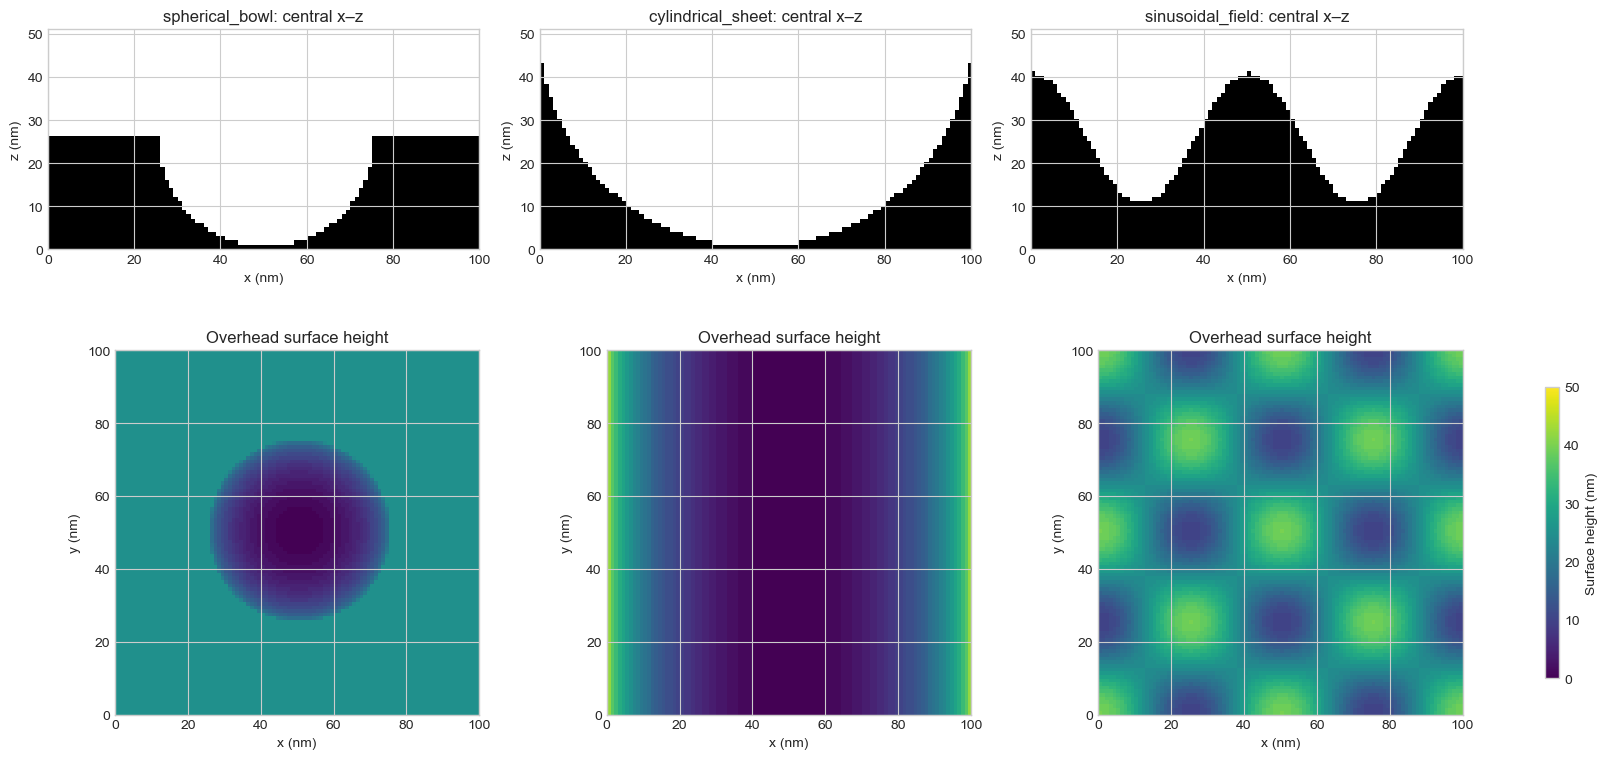

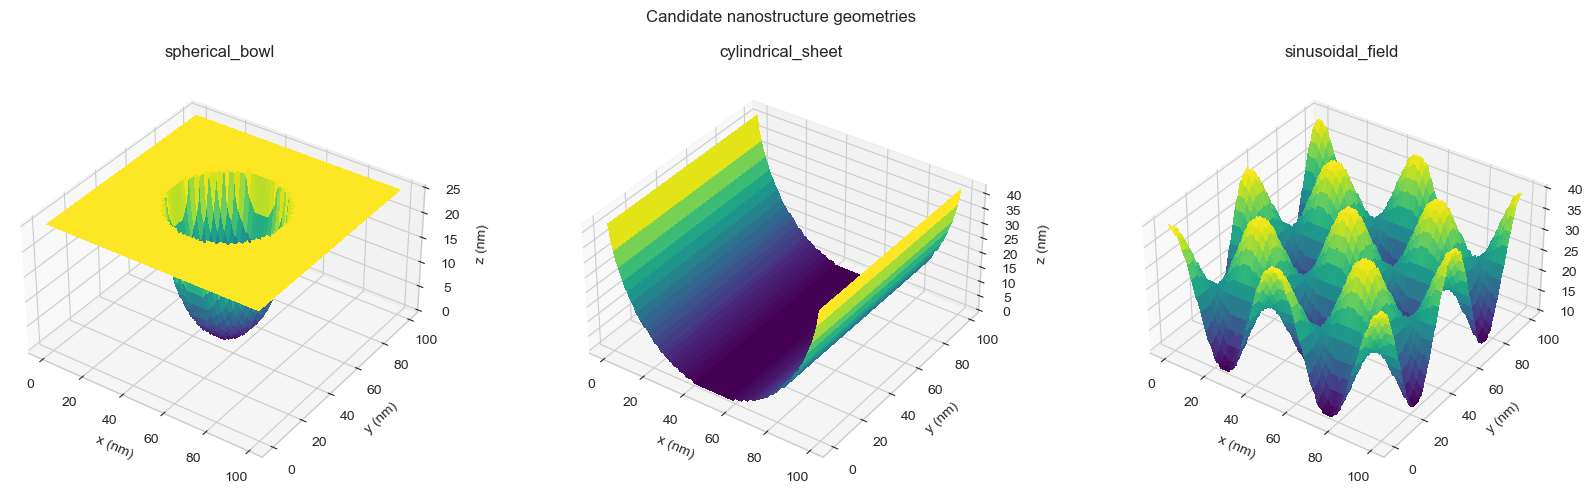

In [145]:
# Compare central cross-sections and top-down height maps.
xc, yc = center_xy_m
y_index = int(round(yc / P.a_m))
z_indices = np.arange(G.Nz + 1)[None, None, :]

fig, axes = plt.subplots(2, len(geometries), figsize=(16, 8), constrained_layout=True)
height_maps_nm = {}
for column, (geometry_name, candidate) in enumerate(geometries.items()):
    solid_slice = candidate.solid_mask[:, y_index, :].T
    axes[0, column].imshow(
        solid_slice, origin="lower", aspect="equal",
        extent=[0, G.Nx * P.a_m / nm, 0, (G.Nz + 1) * P.a_m / nm],
        cmap="Greys",
    )
    axes[0, column].set(xlabel="x (nm)", ylabel="z (nm)", title=f"{geometry_name}: central x–z")

    height_nm = np.max(np.where(candidate.solid_mask, z_indices, -1), axis=2) * P.a_m / nm
    height_maps_nm[geometry_name] = height_nm
    image = axes[1, column].imshow(
        height_nm.T, origin="lower", cmap="viridis", aspect="equal",
        extent=[0, G.Nx * P.a_m / nm, 0, G.Ny * P.a_m / nm],
        vmin=0, vmax=P.H_m / nm,
    )
    axes[1, column].set(xlabel="x (nm)", ylabel="y (nm)", title="Overhead surface height")
fig.colorbar(image, ax=axes[1, :], label="Surface height (nm)", shrink=0.8)
plt.show()

# Continuous-looking 3D renderings of the voxelized upper height fields.
x_nm = np.arange(G.Nx) * P.a_m / nm
y_nm = np.arange(G.Ny) * P.a_m / nm
X_nm, Y_nm = np.meshgrid(x_nm, y_nm, indexing="ij")
fig = plt.figure(figsize=(17, 5))
for column, (geometry_name, height_nm) in enumerate(height_maps_nm.items(), start=1):
    ax = fig.add_subplot(1, len(geometries), column, projection="3d")
    ax.plot_surface(X_nm, Y_nm, height_nm, cmap="viridis", linewidth=0, antialiased=False)
    ax.set(xlabel="x (nm)", ylabel="y (nm)", zlabel="z (nm)", title=geometry_name)
    ax.set_box_aspect((1, 1, 0.55))
    ax.view_init(elev=35, azim=-55)
fig.suptitle("Candidate nanostructure geometries")
plt.tight_layout()
plt.show()

,value
peak_mean_curvature_nm^-1,-2.368705e-01
valley_mean_curvature_nm^-1,2.368705e-01
minimum_gaussian_curvature_nm^-2,-5.268375e-02
maximum_gaussian_curvature_nm^-2,5.610764e-02
max_abs_principal_sum_error_m^-1,2.980232e-08
max_abs_principal_product_error_m^-2,8.000000e+00


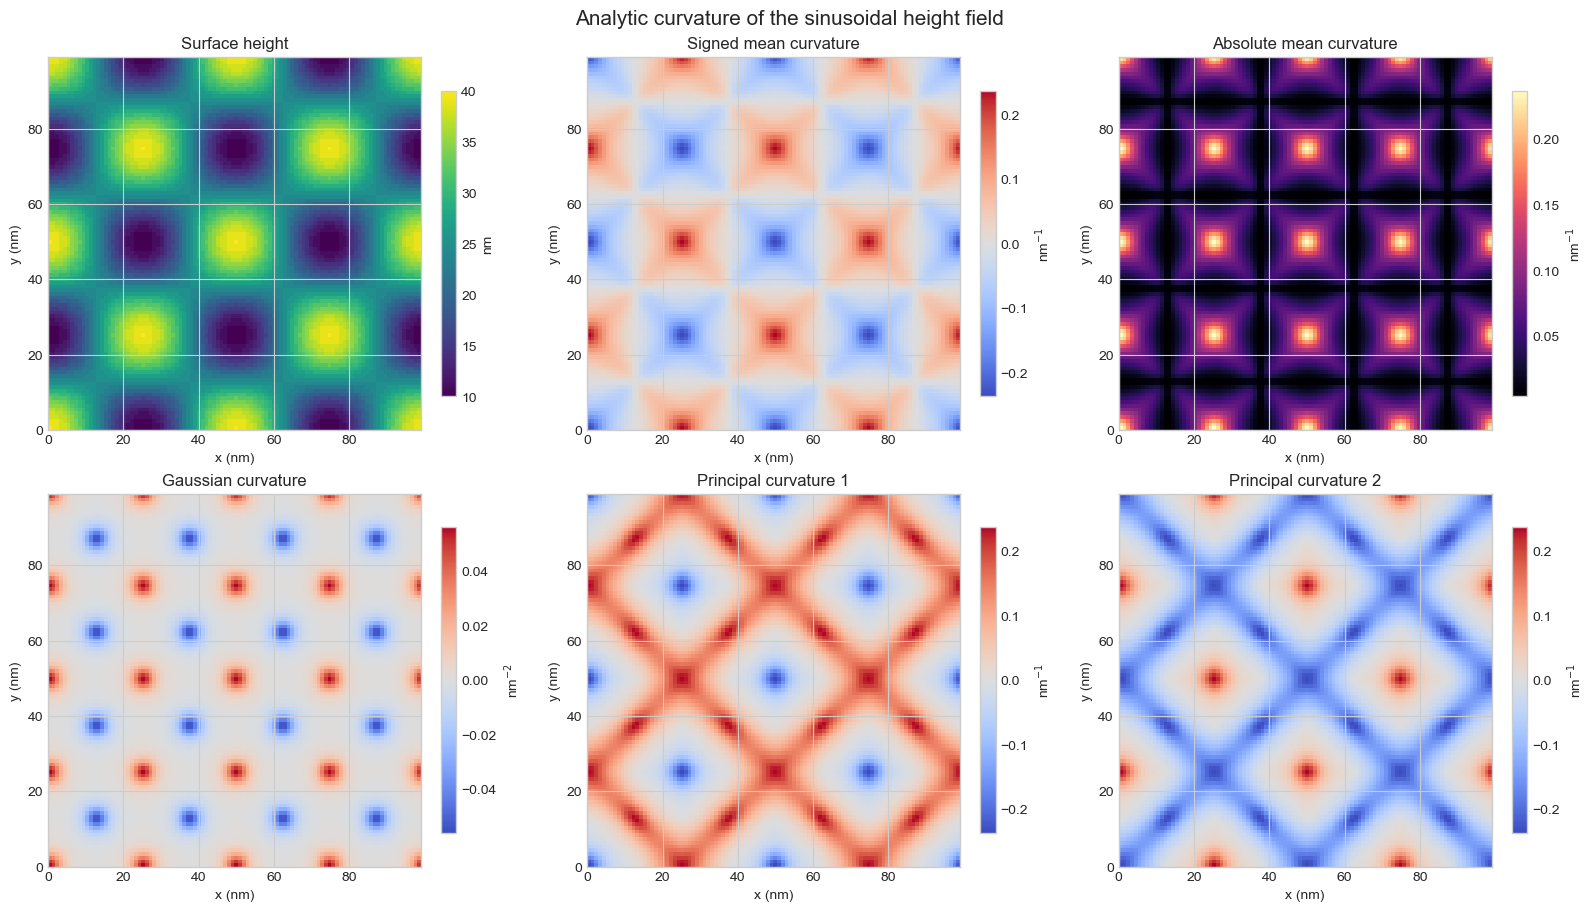

In [146]:
# Validate and inspect the analytic curvature used by the sinusoidal HPC protocol.
sinusoidal_curvature = sinusoidal_surface_curvatures(
    X_nm * nm,
    Y_nm * nm,
    amplitude_m=sinusoidal_geometry.sinusoidal_amplitude_m,
    wavelength_x_m=sinusoidal_geometry.sinusoidal_wavelength_x_m,
    wavelength_y_m=sinusoidal_geometry.sinusoidal_wavelength_y_m,
    phase_x_rad=sinusoidal_geometry.sinusoidal_phase_x_rad,
    phase_y_rad=sinusoidal_geometry.sinusoidal_phase_y_rad,
)

mean_curvature = sinusoidal_curvature["mean_curvature_m_inv"]
gaussian_curvature = sinusoidal_curvature["gaussian_curvature_m_inv2"]
k1 = sinusoidal_curvature["principal_curvature_1_m_inv"]
k2 = sinusoidal_curvature["principal_curvature_2_m_inv"]

# Internal identities and the adopted upward-normal sign convention.
np.testing.assert_allclose(k1 + k2, 2 * mean_curvature, rtol=1e-12, atol=1e-6)
np.testing.assert_allclose(k1 * k2, gaussian_curvature, rtol=1e-12, atol=100.0)
peak_index = (0, 0)  # cos(kx*x) cos(ky*y) = +1
valley_index = (
    int(round(0.5 * sinusoidal_geometry.sinusoidal_wavelength_x_m / P.a_m)),
    0,
)  # cos(kx*x) cos(ky*y) = -1
assert mean_curvature[peak_index] < 0, "Convex peaks should have negative mean curvature."
assert mean_curvature[valley_index] > 0, "Concave valleys should have positive mean curvature."

curvature_checks = pd.Series({
    "peak_mean_curvature_nm^-1": mean_curvature[peak_index] * nm,
    "valley_mean_curvature_nm^-1": mean_curvature[valley_index] * nm,
    "minimum_gaussian_curvature_nm^-2": gaussian_curvature.min() * nm**2,
    "maximum_gaussian_curvature_nm^-2": gaussian_curvature.max() * nm**2,
    "max_abs_principal_sum_error_m^-1": np.max(np.abs(k1 + k2 - 2 * mean_curvature)),
    "max_abs_principal_product_error_m^-2": np.max(np.abs(k1 * k2 - gaussian_curvature)),
})
display(curvature_checks.to_frame("value"))

curvature_maps = [
    (height_maps_nm["sinusoidal_field"], "Surface height", "nm", "viridis", False),
    (mean_curvature * nm, "Signed mean curvature", r"nm$^{-1}$", "coolwarm", True),
    (np.abs(mean_curvature) * nm, "Absolute mean curvature", r"nm$^{-1}$", "magma", False),
    (gaussian_curvature * nm**2, "Gaussian curvature", r"nm$^{-2}$", "coolwarm", True),
    (k1 * nm, "Principal curvature 1", r"nm$^{-1}$", "coolwarm", True),
    (k2 * nm, "Principal curvature 2", r"nm$^{-1}$", "coolwarm", True),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, (values, title, unit, cmap, symmetric) in zip(axes.flat, curvature_maps):
    limit = np.nanmax(np.abs(values)) if symmetric else None
    image = ax.imshow(
        values.T, origin="lower", extent=[x_nm.min(), x_nm.max(), y_nm.min(), y_nm.max()],
        cmap=cmap, vmin=-limit if symmetric else None, vmax=limit if symmetric else None,
        aspect="equal",
    )
    ax.set(xlabel="x (nm)", ylabel="y (nm)", title=title)
    fig.colorbar(image, ax=ax, label=unit, shrink=0.82)
fig.suptitle("Analytic curvature of the sinusoidal height field", fontsize=15)
plt.show()

## 3. Release from every receptor

Each receptor receives the same number of independent release trials. Increase `n_trials_per_location` for production statistics; runtime and output size scale approximately linearly with this value. Bound residence time is included in the measured escape time.

In [147]:
n_trials_per_location = 10  # Increase for production-quality receptor medians.
max_time_s = 1e4  # Increase for production estimates of the late survival tail.

result = run_escape_assay(
    P,
    geometry,
    release_locations=release_locations,
    n_trials_per_location=n_trials_per_location,
    max_time_s=max_time_s,
    escape_mode="z_plane",
    escape_z_m=escape_z_m,
    receptor_face_ids=receptor_face_ids,
    seed=P.seed,
)

print(f"Completed {len(result.trajectories):,} independent trajectories.")
result.releases

Completed 9,200 independent trajectories.


,location_id,label,source_face_id,release_x_index,release_y_index,release_z_index,release_x_m,release_y_m,release_z_m
0,0,receptor_6650,6650,92,75,24,9.200000e-08,7.500000e-08,2.400000e-08
1,1,receptor_16133,16133,77,33,9,7.700000e-08,3.300000e-08,9.000000e-09
2,2,receptor_13012,13012,46,12,1,4.600000e-08,1.200000e-08,1.000000e-09
3,3,receptor_2925,2925,16,25,13,1.600000e-08,2.500000e-08,1.300000e-08
4,4,receptor_6925,6925,94,12,29,9.400000e-08,1.200000e-08,2.900000e-08
...,...,...,...,...,...,...,...,...,...
915,915,receptor_10638,10638,22,38,9,2.200000e-08,3.800000e-08,9.000000e-09
916,916,receptor_16506,16506,81,6,12,8.100000e-08,6.000000e-09,1.200000e-08
917,917,receptor_12587,12587,41,87,1,4.100000e-08,8.700000e-08,1.000000e-09
918,918,receptor_11501,11501,31,1,4,3.100000e-08,1.000000e-09,4.000000e-09


## 4. Receptor-resolved rebinding and escape statistics

In [148]:
trajectories = result.trajectories
receptor_summary = summarize_receptor_trajectories(result)
receptor_summary.head()

,location_id,label,n_trials,n_escaped,escape_probability,median_observation_time_s,mean_observation_time_s,median_escape_time_s,median_rebindings,mean_rebindings,probability_any_rebinding,median_self_rebindings,median_cross_rebindings,mean_bound_time_s,source_face_id,release_x_m,release_y_m,release_z_m,receptor_id,surface_x_m,surface_y_m,surface_z_m
0,0,receptor_6650,10,10,1.0,406.213022,457.479777,406.213022,4.0,4.2,1.0,0.0,4.0,457.479703,6650,9.200000e-08,7.500000e-08,2.400000e-08,315,9.250000e-08,7.500000e-08,2.400000e-08
1,1,receptor_16133,10,10,1.0,853.265636,836.169738,853.265636,8.5,7.8,1.0,0.0,8.0,836.169577,16133,7.700000e-08,3.300000e-08,9.000000e-09,803,7.700000e-08,3.300000e-08,8.500000e-09
2,2,receptor_13012,10,10,1.0,531.342090,509.026980,531.342090,3.0,3.5,0.8,0.0,3.0,509.026879,13012,4.600000e-08,1.200000e-08,1.000000e-09,631,4.600000e-08,1.200000e-08,5.000000e-10
3,3,receptor_2925,10,10,1.0,717.808307,677.704106,717.808307,5.5,5.2,0.9,0.0,4.5,677.704039,2925,1.600000e-08,2.500000e-08,1.300000e-08,142,1.550000e-08,2.500000e-08,1.300000e-08
4,4,receptor_6925,10,10,1.0,208.897487,360.067493,208.897487,2.0,2.9,0.8,0.0,1.5,360.067446,6925,9.400000e-08,1.200000e-08,2.900000e-08,334,9.450000e-08,1.200000e-08,2.900000e-08


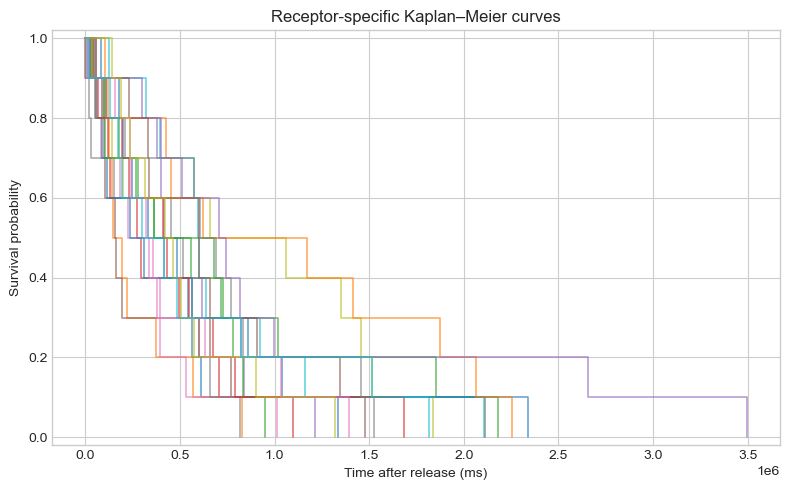

In [149]:
# Plot a representative subset; all receptor-specific curves remain in result.survival.
representative_location_ids = np.linspace(
    0, len(release_locations) - 1, 20, dtype=int
)
fig, ax = plt.subplots(figsize=(8, 5))
plot_kaplan_meier_curves(
    result.survival,
    location_ids=representative_location_ids,
    ax=ax,
)
plt.tight_layout()
plt.show()

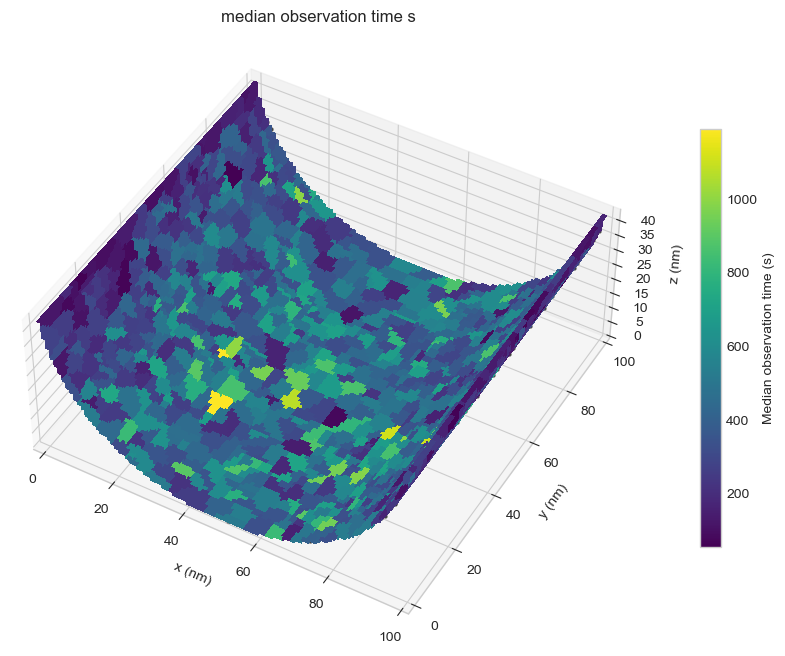

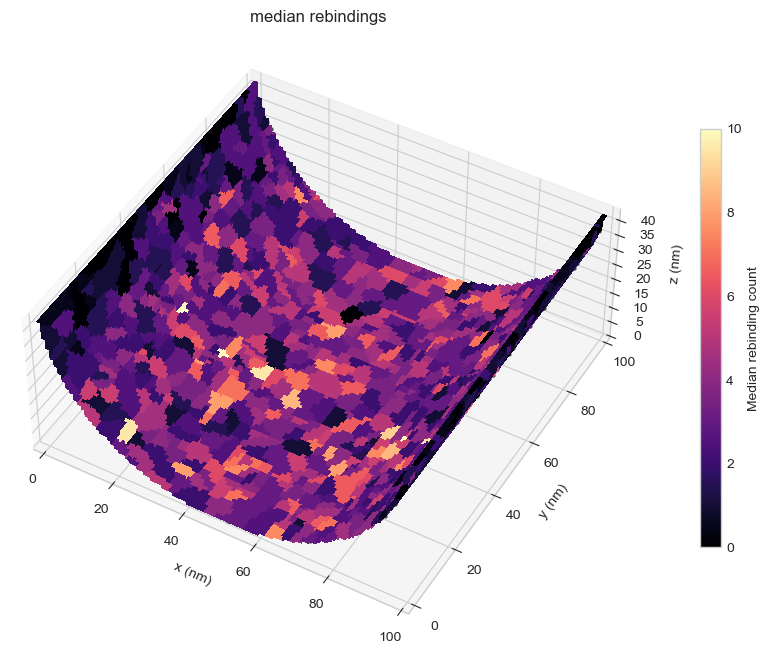

In [150]:
fig_time, ax_time, surface_time = plot_surface_metric_3d(
    geometry, receptor_summary, "median_observation_time_s",
    a_m=P.a_m, surface_face_ids=G.reactive_face_ids,
    colorbar_label="Median observation time (s)", show_receptors=True, figsize=(12,8),
)
ax_time.view_init(elev=45, azim=-60)
plt.show()

fig_rebinding, ax_rebinding, surface_rebinding = plot_surface_metric_3d(
    geometry, receptor_summary, "median_rebindings",
    a_m=P.a_m, surface_face_ids=G.reactive_face_ids, cmap="magma",
    colorbar_label="Median rebinding count", show_receptors=True, figsize=(12,8),
)
ax_rebinding.view_init(elev=45, azim=-60)
plt.show()

## 5. Estimate effective receptor occupancy versus concentration

The escape-derived estimate uses the arithmetic mean cumulative bound time across the initial binding interval and every rebinding interval,

$$\theta_{eff}(C)=\frac{k_{on}C\langle T_{B,total}\rangle}{1+k_{on}C\langle T_{B,total}\rangle}.$$

The classical comparison is $\theta_{classical}=k_{on}C/(k_{on}C+k_{off})$. The shaded band shows receptor-to-receptor variation in the escape-derived estimate, not statistical confidence. If censoring is appreciable, the observed cumulative bound time is truncated at `max_time_s` and the corresponding occupancy estimate is generally a lower bound.

,value
n_trajectories,9.200000e+03
censoring_fraction,0.000000e+00
mean_cumulative_bound_time_s,5.551950e+02
median_cumulative_bound_time_s,3.711567e+02
classical_single_interval_mean_s,1.000000e+02
k_off_times_mean_bound_time,5.551950e+00
effective_C50_M,1.801169e-10
classical_C50_M,1.000000e-09
C50_shift_effective_over_classical,1.801169e-01


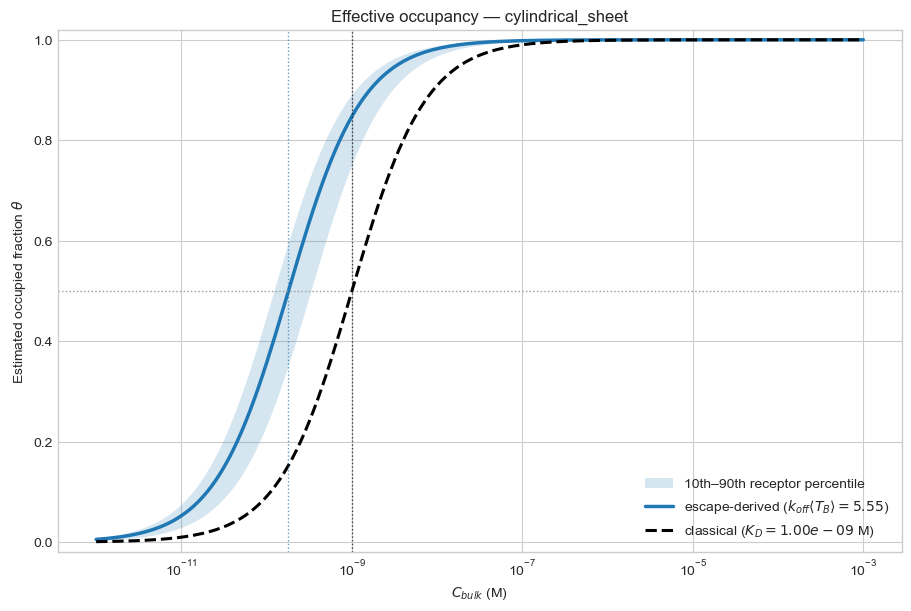

In [151]:
OCCUPANCY_CONCENTRATIONS_M = np.logspace(-12, -3, 181)
PLANAR_REFERENCE_MEAN_BOUND_TIME_S = None
# Set the value above to the matched planar run's mean cumulative bound time
# to add a planar-calibrated nanostructure-retention curve.

def occupancy_from_bound_time(concentration_M, mean_bound_time_s, k_on_M_inv_s):
    q = float(k_on_M_inv_s) * np.asarray(concentration_M, dtype=float) * np.asarray(mean_bound_time_s, dtype=float)
    return q / (1.0 + q)

mean_bound_time_s = float(trajectories['total_bound_time_s'].mean())
median_bound_time_s = float(trajectories['total_bound_time_s'].median())
censoring_fraction = float(trajectories['censored'].mean())
classical_bound_time_s = np.inf if P.k_off_s <= 0 else 1.0 / P.k_off_s
effective_binding_intervals = P.k_off_s * mean_bound_time_s
effective_c50_M = (
    np.inf if P.k_on_M_inv_s <= 0 or mean_bound_time_s <= 0
    else 1.0 / (P.k_on_M_inv_s * mean_bound_time_s)
)
classical_c50_M = np.inf if P.k_on_M_inv_s <= 0 else P.k_off_s / P.k_on_M_inv_s

occupancy_diagnostics = pd.Series({
    'n_trajectories': len(trajectories),
    'censoring_fraction': censoring_fraction,
    'mean_cumulative_bound_time_s': mean_bound_time_s,
    'median_cumulative_bound_time_s': median_bound_time_s,
    'classical_single_interval_mean_s': classical_bound_time_s,
    'k_off_times_mean_bound_time': effective_binding_intervals,
    'effective_C50_M': effective_c50_M,
    'classical_C50_M': classical_c50_M,
    'C50_shift_effective_over_classical': effective_c50_M / classical_c50_M,
}, name=SELECTED_GEOMETRY)
display(occupancy_diagnostics.to_frame('value'))
if censoring_fraction > 0.05:
    print(
        f'Warning: {censoring_fraction:.1%} of trajectories are censored. '
        'Increase max_time_s and verify convergence of the mean cumulative bound time.'
    )

theta_effective = occupancy_from_bound_time(
    OCCUPANCY_CONCENTRATIONS_M, mean_bound_time_s, P.k_on_M_inv_s
)
association_rate = P.k_on_M_inv_s * OCCUPANCY_CONCENTRATIONS_M
theta_classical = association_rate / (association_rate + P.k_off_s)

receptor_bound_times_s = receptor_summary['mean_bound_time_s'].to_numpy(float)
receptor_theta = occupancy_from_bound_time(
    OCCUPANCY_CONCENTRATIONS_M[:, None],
    receptor_bound_times_s[None, :],
    P.k_on_M_inv_s,
)
theta_receptor_low, theta_receptor_high = np.nanquantile(
    receptor_theta, [0.1, 0.9], axis=1
)

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.fill_between(
    OCCUPANCY_CONCENTRATIONS_M, theta_receptor_low, theta_receptor_high,
    color='tab:blue', alpha=0.18, linewidth=0, label='10th–90th receptor percentile',
)
ax.plot(
    OCCUPANCY_CONCENTRATIONS_M, theta_effective, color='tab:blue', linewidth=2.5,
    label=rf'escape-derived ($k_{{off}}\langle T_B\rangle={effective_binding_intervals:.3g}$)',
)
ax.plot(
    OCCUPANCY_CONCENTRATIONS_M, theta_classical, color='black', linestyle='--', linewidth=2.2,
    label=rf'classical ($K_D={classical_c50_M:.2e}$ M)',
)

if PLANAR_REFERENCE_MEAN_BOUND_TIME_S is not None:
    planar_reference_time_s = float(PLANAR_REFERENCE_MEAN_BOUND_TIME_S)
    if planar_reference_time_s <= 0:
        raise ValueError('PLANAR_REFERENCE_MEAN_BOUND_TIME_S must be positive.')
    retention_enhancement = mean_bound_time_s / planar_reference_time_s
    calibrated_bound_time_s = retention_enhancement / P.k_off_s
    theta_calibrated = occupancy_from_bound_time(
        OCCUPANCY_CONCENTRATIONS_M, calibrated_bound_time_s, P.k_on_M_inv_s
    )
    ax.plot(
        OCCUPANCY_CONCENTRATIONS_M, theta_calibrated, color='tab:orange',
        linestyle='-.', linewidth=2.2,
        label=rf'planar-calibrated ($E_{{retention}}={retention_enhancement:.3g}$)',
    )

ax.axhline(0.5, color='0.6', linestyle=':', linewidth=1)
ax.axvline(classical_c50_M, color='black', linestyle=':', linewidth=1, alpha=0.7)
ax.axvline(effective_c50_M, color='tab:blue', linestyle=':', linewidth=1, alpha=0.7)
ax.set_xscale('log')
ax.set(
    xlabel=r'$C_{bulk}$ (M)', ylabel=r'Estimated occupied fraction $\theta$',
    ylim=(-0.02, 1.02), title=f'Effective occupancy — {SELECTED_GEOMETRY}',
)
ax.legend(loc='best')
plt.show()


## 6. Optional export

Set `save_results = True` to create a self-contained run folder. The bundle includes trajectories, survival curves, receptor summaries, parameters, and the exact voxelized geometry needed to reproduce every plot without rerunning the assay.

In [152]:
save_results = False
output_directory = Path("data/escape_assay") / SELECTED_GEOMETRY

if save_results:
    saved_directory = export_escape_assay_run(
        result,
        output_directory,
        receptor_summary=receptor_summary,
    )
    print(f"Saved self-contained run to {saved_directory.resolve()}")

## 7. Re-create plots from a previous run folder

Point `previous_run_directory` at any folder produced by `export_escape_assay_run`. Loading does not rerun the Monte Carlo assay. The exact geometry, parameters, tables, and receptor summaries are restored from disk.

In [153]:
plot_previous_run = False
previous_run_directory = Path("data/escape_assay/spherical_bowl")

if plot_previous_run:
    archived_run = load_escape_assay_run(previous_run_directory)
    print(archived_run.metadata)

    ax, _ = plot_kaplan_meier_from_folder(
        previous_run_directory,
        max_curves=20,
    )
    plt.show()

    fig, ax, archived_surface_time, _ = plot_surface_metric_from_folder(
        previous_run_directory,
        "median_observation_time_s",
        colorbar_label="Median observation time (s)",
        show_receptors=True,
    )
    plt.show()

    fig, ax, archived_surface_rebinding, _ = plot_surface_metric_from_folder(
        previous_run_directory,
        "median_rebindings",
        cmap="magma",
        colorbar_label="Median rebinding count",
        show_receptors=True,
    )
    plt.show()